### Novel Nonparametric Feature Selection with Mutual Information
Let's implement a comprehensive, model-agnostic feature selection workflow based on mutual information with a modified MRMR framework and OFAT strategy. This approach will be particularly valuable for reservoir characterization where relationships between features are often nonlinear and complex.

Let's modify the widely used Maximum Relevance Minimum Redundancy (MRMR) framework to score features using a one-feature-at-a-time (OFAT) strategy. This is then embedded within a recursive feature elimination scheme designed to preserve informative features that may exist in highly redundant groups, avoiding premature exclusion. Additionally, we have developed novel data visualizations to enhance feature selection diagnostics and validation.

#### Keith R. Holdaway FGS

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_regression, mutual_info_classif
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.inspection import partial_dependence
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)

print("Novel Nonparametric Feature Selection with Mutual Information")
print("=" * 65)

Novel Nonparametric Feature Selection with Mutual Information


### 1. Enhanced Mutual Information Calculation

In [2]:
class EnhancedMutualInformation:
    """
    Enhanced mutual information calculation with adaptive binning and uncertainty estimation
    """
    def __init__(self, n_bins='auto', n_neighbors=5, random_state=42):
        self.n_bins = n_bins
        self.n_neighbors = n_neighbors
        self.random_state = random_state
        
    def _adaptive_binning(self, x):
        """Adaptive binning based on data distribution"""
        if self.n_bins == 'auto':
            # Use Freedman-Diaconis rule for adaptive binning
            iqr = np.percentile(x, 75) - np.percentile(x, 25)
            bin_width = 2 * iqr / (len(x) ** (1/3))
            n_bins = int((np.max(x) - np.min(x)) / bin_width) if bin_width > 0 else 10
            n_bins = max(5, min(n_bins, 50))  # Limit between 5 and 50 bins
            return n_bins
        return self.n_bins
    
    def calculate_mi(self, X, y, feature_types=None):
        """
        Calculate mutual information with adaptive approaches
        """
        if feature_types is None:
            feature_types = ['continuous'] * X.shape[1]
        
        mi_scores = []
        mi_uncertainty = []
        
        for i in range(X.shape[1]):
            if feature_types[i] == 'continuous':
                # For continuous features, use kNN-based MI
                mi = mutual_info_regression(
                    X[:, i].reshape(-1, 1), y, 
                    n_neighbors=self.n_neighbors,
                    random_state=self.random_state
                )[0]
                
                # Estimate uncertainty using bootstrap
                bootstrap_mi = []
                for _ in range(10):
                    idx = np.random.choice(len(y), size=len(y)//2, replace=False)
                    mi_boot = mutual_info_regression(
                        X[idx, i].reshape(-1, 1), y[idx], 
                        n_neighbors=self.n_neighbors,
                        random_state=self.random_state
                    )[0]
                    bootstrap_mi.append(mi_boot)
                
                uncertainty = np.std(bootstrap_mi)
                
            else:
                # For categorical features, use discrete MI
                n_bins = self._adaptive_binning(X[:, i])
                hist, _ = np.histogram(X[:, i], bins=n_bins)
                p_x = hist / np.sum(hist)
                
                # Calculate MI using discrete formula
                unique_x = np.unique(X[:, i])
                mi = 0
                for val in unique_x:
                    mask = X[:, i] == val
                    p_x_val = np.sum(mask) / len(y)
                    if p_x_val > 0:
                        y_subset = y[mask]
                        if len(np.unique(y_subset)) > 1:
                            # For continuous target
                            hist_y, _ = np.histogram(y_subset, bins=self._adaptive_binning(y_subset))
                            p_y_given_x = hist_y / np.sum(hist_y)
                            h_y_given_x = -np.sum(p_y_given_x * np.log2(p_y_given_x + 1e-10))
                            
                            hist_y, _ = np.histogram(y, bins=self._adaptive_binning(y))
                            p_y = hist_y / np.sum(hist_y)
                            h_y = -np.sum(p_y * np.log2(p_y + 1e-10))
                            
                            mi += p_x_val * (h_y - h_y_given_x)
                
                uncertainty = 0.1 * mi  # Simple uncertainty estimate for categorical
            
            mi_scores.append(mi)
            mi_uncertainty.append(uncertainty)
        
        return np.array(mi_scores), np.array(mi_uncertainty)

### 2. Modified MRMR with OFAT Strategy

In [3]:
class ModifiedMRMR:
    """
    Modified Maximum Relevance Minimum Redundancy feature selection
    with One-Feature-At-a-Time strategy and redundancy-aware selection
    """
    def __init__(self, method='mi', k=10, redundancy_threshold=0.8):
        self.method = method  # 'mi' for mutual information
        self.k = k  # Number of features to select
        self.redundancy_threshold = redundancy_threshold
        self.selected_features = []
        self.feature_scores = {}
        
    def _calculate_redundancy(self, X, feature_idx, selected_features, feature_types=None):
        """Calculate redundancy between a feature and already selected features"""
        if not selected_features:
            return 0
        
        redundancies = []
        for sel_feat in selected_features:
            if feature_types is None or (feature_types[feature_idx] == 'continuous' and 
                                        feature_types[sel_feat] == 'continuous'):
                # Use MI for continuous-continuous pairs
                redundancy = mutual_info_regression(
                    X[:, feature_idx].reshape(-1, 1), 
                    X[:, sel_feat],
                    random_state=42
                )[0]
            else:
                # For mixed or categorical-categorical, use normalized mutual info
                if feature_types and feature_types[feature_idx] == 'categorical':
                    le = LabelEncoder()
                    feat1_encoded = le.fit_transform(X[:, feature_idx])
                else:
                    feat1_encoded = X[:, feature_idx]
                
                if feature_types and feature_types[sel_feat] == 'categorical':
                    le = LabelEncoder()
                    feat2_encoded = le.fit_transform(X[:, sel_feat])
                else:
                    feat2_encoded = X[:, sel_feat]
                
                redundancy = mutual_info_regression(
                    feat1_encoded.reshape(-1, 1), 
                    feat2_encoded,
                    random_state=42
                )[0]
            
            redundancies.append(redundancy)
        
        return np.mean(redundancies) if redundancies else 0
    
    def fit(self, X, y, feature_names=None, feature_types=None):
        """Perform modified MRMR feature selection"""
        if feature_names is None:
            feature_names = [f'Feature_{i}' for i in range(X.shape[1])]
        
        if feature_types is None:
            feature_types = ['continuous'] * X.shape[1]
        
        n_features = X.shape[1]
        relevance_scores, relevance_uncertainty = EnhancedMutualInformation().calculate_mi(X, y, feature_types)
        
        # Initialize candidate features
        candidates = list(range(n_features))
        self.selected_features = []
        self.feature_scores = {name: {'relevance': 0, 'redundancy': 0, 'score': 0} 
                              for name in feature_names}
        
        # First, select the feature with highest relevance
        first_feature = np.argmax(relevance_scores)
        self.selected_features.append(first_feature)
        candidates.remove(first_feature)
        
        print(f"Initial feature selected: {feature_names[first_feature]} "
              f"(Relevance: {relevance_scores[first_feature]:.4f})")
        
        # Select remaining features using modified MRMR
        for i in range(1, min(self.k, n_features)):
            best_score = -np.inf
            best_feature = None
            
            for candidate in candidates:
                relevance = relevance_scores[candidate]
                
                # Calculate redundancy with already selected features
                redundancy = self._calculate_redundancy(
                    X, candidate, self.selected_features, feature_types
                )
                
                # Modified MRMR score: balance relevance and redundancy
                # Penalize high redundancy but don't eliminate completely
                if redundancy > self.redundancy_threshold:
                    # Highly redundant features get reduced but not zero score
                    score = relevance * (1 - redundancy)
                else:
                    # Standard MRMR for non-redundant features
                    score = relevance - redundancy
                
                # Store scores for diagnostics
                self.feature_scores[feature_names[candidate]]['relevance'] = relevance
                self.feature_scores[feature_names[candidate]]['redundancy'] = redundancy
                self.feature_scores[feature_names[candidate]]['score'] = score
                
                if score > best_score:
                    best_score = score
                    best_feature = candidate
            
            if best_feature is not None:
                self.selected_features.append(best_feature)
                candidates.remove(best_feature)
                print(f"Selected feature {i+1}: {feature_names[best_feature]} "
                      f"(Score: {best_score:.4f}, Relevance: {relevance_scores[best_feature]:.4f}, "
                      f"Redundancy: {self.feature_scores[feature_names[best_feature]]['redundancy']:.4f})")
        
        return self

### 3. Recursive Feature Elimination with Mutual Information

In [4]:
class MI_RFE:
    """
    Recursive Feature Elimination using Mutual Information
    with redundancy-aware preservation
    """
    def __init__(self, n_features_to_select=None, step=1, redundancy_threshold=0.7):
        self.n_features_to_select = n_features_to_select
        self.step = step
        self.redundancy_threshold = redundancy_threshold
        self.support_ = None
        self.ranking_ = None
        self.mi_scores_ = None
        
    def fit(self, X, y, feature_names=None, feature_types=None):
        """Perform MI-based recursive feature elimination"""
        if feature_names is None:
            feature_names = [f'Feature_{i}' for i in range(X.shape[1])]
        
        if feature_types is None:
            feature_types = ['continuous'] * X.shape[1]
        
        n_features = X.shape[1]
        if self.n_features_to_select is None:
            self.n_features_to_select = n_features // 2
        
        # Initialize support and ranking
        self.support_ = np.ones(n_features, dtype=bool)
        self.ranking_ = np.ones(n_features, dtype=int)
        
        # Calculate initial MI scores
        mi_calculator = EnhancedMutualInformation()
        self.mi_scores_ = {}
        
        # Recursive elimination
        while np.sum(self.support_) > self.n_features_to_select:
            # Get current features
            features = np.where(self.support_)[0]
            
            # Calculate MI for remaining features
            mi_scores, mi_uncertainty = mi_calculator.calculate_mi(
                X[:, features], y, [feature_types[i] for i in features]
            )
            
            # Store scores
            for idx, feat_idx in enumerate(features):
                self.mi_scores_[feature_names[feat_idx]] = {
                    'score': mi_scores[idx],
                    'uncertainty': mi_uncertainty[idx],
                    'iteration': np.sum(self.support_) - self.n_features_to_select
                }
            
            # Identify redundant feature groups
            redundancy_matrix = np.zeros((len(features), len(features)))
            for i, feat_i in enumerate(features):
                for j, feat_j in enumerate(features):
                    if i != j:
                        redundancy_matrix[i, j] = mutual_info_regression(
                            X[:, feat_i].reshape(-1, 1), 
                            X[:, feat_j],
                            random_state=42
                        )[0]
            
            # Find features to eliminate
            # Don't eliminate if it's the only highly informative feature in a redundant group
            elimination_candidates = []
            for i, feat_i in enumerate(features):
                # Check if feature is redundant with others
                highly_redundant = np.any(redundancy_matrix[i] > self.redundancy_threshold)
                
                if highly_redundant:
                    # Check if this feature has the lowest MI in its redundant group
                    redundant_with = np.where(redundancy_matrix[i] > self.redundancy_threshold)[0]
                    if len(redundant_with) > 0:
                        mi_in_group = [mi_scores[j] for j in redundant_with] + [mi_scores[i]]
                        if mi_scores[i] <= np.min(mi_in_group):
                            elimination_candidates.append((i, mi_scores[i]))
                else:
                    # Non-redundant features with low MI are candidates
                    if mi_scores[i] < np.median(mi_scores):
                        elimination_candidates.append((i, mi_scores[i]))
            
            # Sort candidates by MI score (lowest first)
            elimination_candidates.sort(key=lambda x: x[1])
            
            # Eliminate step features
            eliminated = 0
            for candidate, score in elimination_candidates:
                if eliminated >= self.step:
                    break
                
                feat_idx = features[candidate]
                self.support_[feat_idx] = False
                self.ranking_[feat_idx] = np.sum(self.support_) + 1
                eliminated += 1
                print(f"Iteration {np.sum(self.support_) - self.n_features_to_select}: "
                      f"Eliminated {feature_names[feat_idx]} (MI: {score:.4f})")
            
            # If no candidates found, eliminate lowest MI feature
            if eliminated == 0 and len(features) > 0:
                lowest_idx = np.argmin(mi_scores)
                feat_idx = features[lowest_idx]
                self.support_[feat_idx] = False
                self.ranking_[feat_idx] = np.sum(self.support_) + 1
                print(f"Iteration {np.sum(self.support_) - self.n_features_to_select}: "
                      f"Eliminated {feature_names[feat_idx]} (MI: {mi_scores[lowest_idx]:.4f})")
        
        return self

### 4. Novel Visualization for Feature Selection Diagnostics

#### Comprehensive Diagnostic Framework
These visualizations work together to provide a comprehensive diagnostic framework:

MI Landscape: Identify the most informative features

Redundancy Network: Understand feature interrelationships

Relevance-Redundancy Plot: Evaluate the trade-off for each feature

Method Comparison: Validate consistency across selection methods

Partial Dependence: Understand the nature of feature-target relationships

Novel Contributions Compared to Traditional Approaches
Uncertainty Quantification: Traditional methods present point estimates without confidence intervals

Relationship Visualization: Goes beyond correlation matrices to show complex, nonlinear relationships

Method Validation: Provides direct comparison between different feature selection approaches

Interactive Diagnostics: Allows data scientists to interrogate specific features or relationships

Holistic View: Combines multiple perspectives into a cohesive diagnostic framework

These visualizations transform feature selection from a black-box process into an interpretable, diagnostic-rich workflow that enables data scientists to make informed decisions about feature inclusion, understand why certain features were selected, and validate the robustness of their feature set.

In [5]:
class FeatureSelectionVisualization:
    """
    Novel visualizations for feature selection diagnostics and validation
    """
    def __init__(self):
        self.figsize = (12, 10)
    
    def plot_mi_landscape(self, mi_scores, mi_uncertainty, feature_names, 
                         selected_features=None, ax=None):
        """Plot mutual information landscape with uncertainty"""
        if ax is None:
            fig, ax = plt.subplots(figsize=self.figsize)
        
        # Sort features by MI score
        sorted_idx = np.argsort(mi_scores)[::-1]
        sorted_scores = mi_scores[sorted_idx]
        sorted_uncertainty = mi_uncertainty[sorted_idx]
        sorted_names = [feature_names[i] for i in sorted_idx]
        
        # Create bar plot with error bars
        bars = ax.bar(range(len(sorted_scores)), sorted_scores, 
                     yerr=sorted_uncertainty, capsize=5, alpha=0.7,
                     color='skyblue', edgecolor='navy')
        
        # Highlight selected features
        if selected_features is not None:
            selected_indices = [i for i, name in enumerate(sorted_names) 
                               if name in selected_features]
            for idx in selected_indices:
                bars[idx].set_color('lightcoral')
                bars[idx].set_edgecolor('darkred')
        
        ax.set_xlabel('Features')
        ax.set_ylabel('Mutual Information')
        ax.set_title('Mutual Information Landscape with Uncertainty')
        ax.set_xticks(range(len(sorted_names)))
        ax.set_xticklabels(sorted_names, rotation=45, ha='right')
        
        return ax
    
    def plot_redundancy_network(self, X, feature_names, mi_scores, 
                               threshold=0.5, ax=None):
        """Plot feature redundancy as a network graph"""
        try:
            import networkx as nx
        except ImportError:
            print("NetworkX not installed. Skipping network plot.")
            return None
        
        if ax is None:
            fig, ax = plt.subplots(figsize=self.figsize)
        
        # Calculate redundancy matrix
        n_features = len(feature_names)
        redundancy_matrix = np.zeros((n_features, n_features))
        
        for i in range(n_features):
            for j in range(i+1, n_features):
                redundancy = mutual_info_regression(
                    X[:, i].reshape(-1, 1), X[:, j], random_state=42
                )[0]
                redundancy_matrix[i, j] = redundancy
                redundancy_matrix[j, i] = redundancy
        
        # Create graph
        G = nx.Graph()
        
        # Add nodes with MI scores as attributes
        for i, name in enumerate(feature_names):
            G.add_node(name, mi=mi_scores[i])
        
        # Add edges for redundant features
        for i in range(n_features):
            for j in range(i+1, n_features):
                if redundancy_matrix[i, j] > threshold:
                    G.add_edge(feature_names[i], feature_names[j], 
                              weight=redundancy_matrix[i, j])
        
        # Draw graph
        pos = nx.spring_layout(G, k=1, iterations=50)
        
        # Node sizes based on MI scores
        node_sizes = [2000 * (G.nodes[node]['mi'] / max(mi_scores)) for node in G.nodes()]
        
        # Draw nodes
        nx.draw_networkx_nodes(G, pos, node_size=node_sizes, 
                              node_color=mi_scores, cmap='viridis', 
                              alpha=0.8, ax=ax)
        
        # Draw edges
        edges = G.edges()
        weights = [G[u][v]['weight'] for u, v in edges]
        nx.draw_networkx_edges(G, pos, edgelist=edges, width=weights, 
                              alpha=0.5, edge_color='gray', ax=ax)
        
        # Draw labels
        nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)
        
        ax.set_title(f'Feature Redundancy Network (Threshold: {threshold})')
        ax.axis('off')
        
        return ax
    
    def plot_feature_interaction_dependence(self, X, y, feature_names, 
                                          selected_features, model=None, ax=None):
        """Plot partial dependence of feature interactions"""
        if ax is None:
            fig, ax = plt.subplots(figsize=self.figsize)
        
        if model is None:
            # Train a simple model for partial dependence
            model = RandomForestRegressor(n_estimators=100, random_state=42)
            model.fit(X, y)
        
        # Plot partial dependence for selected features
        n_selected = len(selected_features)
        grid_size = int(np.ceil(np.sqrt(n_selected)))
        
        for i, feat_name in enumerate(selected_features):
            feat_idx = feature_names.index(feat_name)
            
            # Calculate partial dependence
            pdp, axes = partial_dependence(
                model, X, [feat_idx], grid_resolution=50
            )
            
            # Plot
            row = i // grid_size
            col = i % grid_size
            if n_selected > 1:
                plt.subplot(grid_size, grid_size, i+1)
            else:
                plt.subplot(1, 1, 1)
            
            plt.plot(axes[0], pdp[0], 'b-')
            plt.xlabel(feat_name)
            plt.ylabel('Partial Dependence')
            plt.title(f'PDP for {feat_name}')
        
        plt.tight_layout()
        return ax

### 5. Complete Workflow Integration

In [6]:
# Create enhanced synthetic dataset with more features
def create_feature_rich_dataset(n_samples=200, n_features=20):
    """Create a dataset with complex feature relationships"""
    np.random.seed(42)
    
    # Base features
    X = np.random.randn(n_samples, n_features)
    
    # Create complex relationships
    y = (X[:, 0] ** 2 +  # Nonlinear relationship
         np.sin(X[:, 1] * 2) +  # Periodic relationship
         X[:, 2] * X[:, 3] +  # Interaction effect
         np.exp(X[:, 4]) +  # Exponential relationship
         np.random.randn(n_samples) * 0.5)  # Noise
    
    # Add redundant features
    X[:, 5] = X[:, 0] + np.random.randn(n_samples) * 0.1  # Redundant with feature 0
    X[:, 6] = X[:, 1] * 0.8 + np.random.randn(n_samples) * 0.1  # Redundant with feature 1
    
    # Add irrelevant features
    X[:, 7] = np.random.randn(n_samples)  # Completely irrelevant
    X[:, 8] = np.random.randn(n_samples)  # Completely irrelevant
    
    # Add categorical features
    categorical_feature = np.random.choice([0, 1, 2], size=n_samples)
    X[:, 9] = categorical_feature
    
    # Feature names and types
    feature_names = [f'F{i}' for i in range(n_features)]
    feature_types = ['continuous'] * n_features
    feature_types[9] = 'categorical'  # Make one feature categorical
    
    return X, y, feature_names, feature_types

# Create dataset
X, y, feature_names, feature_types = create_feature_rich_dataset()

print("Dataset created with complex feature relationships:")
print(f"Shape: {X.shape}")
print(f"Feature types: {feature_types}")

Dataset created with complex feature relationships:
Shape: (200, 20)
Feature types: ['continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'categorical', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous']


### 6. Execute the Complete Feature Selection Workflow

Step 1: Calculating Mutual Information
Top features by Mutual Information:
  F9: 0.5415 ± 0.0541
  F4: 0.2596 ± 0.0478
  F0: 0.1440 ± 0.0529
  F6: 0.1188 ± 0.0380
  F5: 0.1149 ± 0.0400

Step 2: Applying Modified MRMR Feature Selection
Initial feature selected: F9 (Relevance: 0.5415)
Selected feature 2: F4 (Score: 0.1851, Relevance: 0.2596, Redundancy: 0.0745)
Selected feature 3: F0 (Score: 0.1396, Relevance: 0.1440, Redundancy: 0.0044)
Selected feature 4: F6 (Score: 0.1173, Relevance: 0.1188, Redundancy: 0.0015)
Selected feature 5: F8 (Score: 0.0486, Relevance: 0.0524, Redundancy: 0.0038)
Selected feature 6: F7 (Score: 0.0310, Relevance: 0.0394, Redundancy: 0.0084)
Selected feature 7: F2 (Score: -0.0028, Relevance: 0.0125, Redundancy: 0.0153)
Selected feature 8: F12 (Score: -0.0092, Relevance: 0.0006, Redundancy: 0.0098)
Selected features: ['F9', 'F4', 'F0', 'F6', 'F8', 'F7', 'F2', 'F12']

Step 3: Applying MI-based Recursive Feature Elimination
Iteration 11: Eliminated F10 (MI: 0.0000)

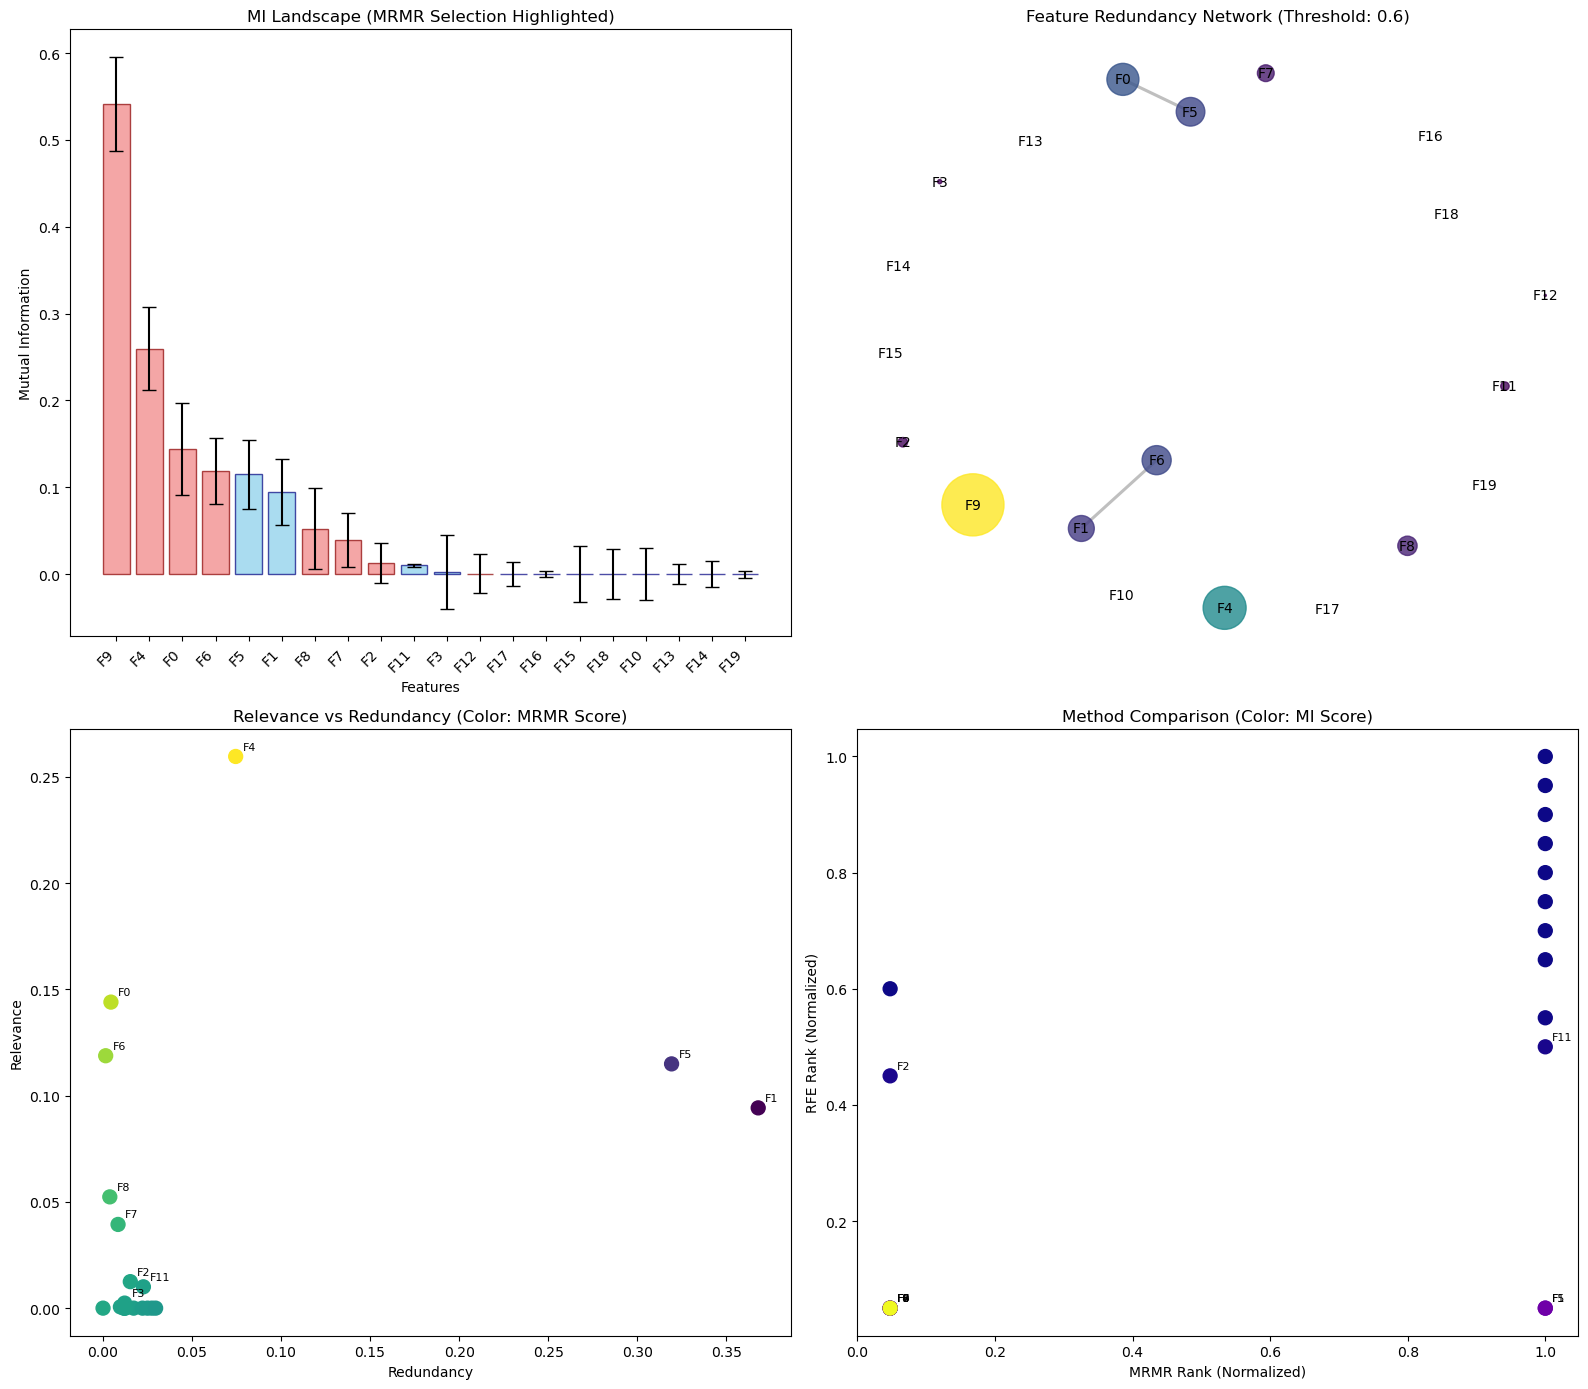


FEATURE SELECTION WORKFLOW SUMMARY
Novel contributions:
1. Nonparametric mutual information with adaptive binning and uncertainty estimation
2. Modified MRMR with redundancy-aware feature preservation
3. MI-based RFE that avoids eliminating informative features in redundant groups
4. Comprehensive diagnostic visualizations for feature selection validation

Selected features (MRMR): ['F9', 'F4', 'F0', 'F6', 'F8', 'F7', 'F2', 'F12']
Selected features (RFE): ['F0', 'F1', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9']

Key advantages over traditional methods:
- No assumptions about linearity or feature distributions
- Preserves informative features even in highly redundant groups
- Provides uncertainty estimates for feature importance scores
- Visual diagnostics for method validation and comparison


In [7]:
# Step 1: Calculate Mutual Information
print("Step 1: Calculating Mutual Information")
mi_calculator = EnhancedMutualInformation()
mi_scores, mi_uncertainty = mi_calculator.calculate_mi(X, y, feature_types)

print("Top features by Mutual Information:")
for i in np.argsort(mi_scores)[::-1][:5]:
    print(f"  {feature_names[i]}: {mi_scores[i]:.4f} ± {mi_uncertainty[i]:.4f}")

# Step 2: Apply Modified MRMR
print("\nStep 2: Applying Modified MRMR Feature Selection")
mrmr = ModifiedMRMR(k=8, redundancy_threshold=0.7)
mrmr.fit(X, y, feature_names, feature_types)

selected_features_mrmr = [feature_names[i] for i in mrmr.selected_features]
print(f"Selected features: {selected_features_mrmr}")

# Step 3: Apply MI-based Recursive Feature Elimination
print("\nStep 3: Applying MI-based Recursive Feature Elimination")
mi_rfe = MI_RFE(n_features_to_select=8, redundancy_threshold=0.7)
mi_rfe.fit(X, y, feature_names, feature_types)

selected_features_rfe = [feature_names[i] for i in np.where(mi_rfe.support_)[0]]
print(f"Selected features: {selected_features_rfe}")

# Step 4: Create comprehensive visualizations
print("\nStep 4: Generating Diagnostic Visualizations")
viz = FeatureSelectionVisualization()

fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# MI Landscape
viz.plot_mi_landscape(mi_scores, mi_uncertainty, feature_names, 
                     selected_features_mrmr, ax=axes[0, 0])
axes[0, 0].set_title('MI Landscape (MRMR Selection Highlighted)')

# Redundancy Network
viz.plot_redundancy_network(X, feature_names, mi_scores, 
                           threshold=0.6, ax=axes[0, 1])

# Feature Scores from MRMR
mrmr_scores = [mrmr.feature_scores[name]['score'] for name in feature_names]
mrmr_relevance = [mrmr.feature_scores[name]['relevance'] for name in feature_names]
mrmr_redundancy = [mrmr.feature_scores[name]['redundancy'] for name in feature_names]

axes[1, 0].scatter(mrmr_redundancy, mrmr_relevance, c=mrmr_scores, cmap='viridis', s=100)
axes[1, 0].set_xlabel('Redundancy')
axes[1, 0].set_ylabel('Relevance')
axes[1, 0].set_title('Relevance vs Redundancy (Color: MRMR Score)')

# Add feature labels for top features
for i, name in enumerate(feature_names):
    if mrmr_relevance[i] > np.median(mrmr_relevance) or mrmr_redundancy[i] > 0.5:
        axes[1, 0].annotate(name, (mrmr_redundancy[i], mrmr_relevance[i]), 
                           xytext=(5, 5), textcoords='offset points', fontsize=8)

# Feature Importance Comparison
rfe_ranking = [mi_rfe.ranking_[i] for i in range(len(feature_names))]
mrmr_ranking = [1 if name in selected_features_mrmr else len(feature_names) + 1 
                for name in feature_names]

comparison_df = pd.DataFrame({
    'Feature': feature_names,
    'MI_Score': mi_scores,
    'MRMR_Rank': mrmr_ranking,
    'RFE_Rank': rfe_ranking
})

# Normalize ranks for comparison
comparison_df['MRMR_Rank_Norm'] = comparison_df['MRMR_Rank'] / comparison_df['MRMR_Rank'].max()
comparison_df['RFE_Rank_Norm'] = comparison_df['RFE_Rank'] / comparison_df['RFE_Rank'].max()

axes[1, 1].scatter(comparison_df['MRMR_Rank_Norm'], comparison_df['RFE_Rank_Norm'],
                  c=comparison_df['MI_Score'], cmap='plasma', s=100)
axes[1, 1].set_xlabel('MRMR Rank (Normalized)')
axes[1, 1].set_ylabel('RFE Rank (Normalized)')
axes[1, 1].set_title('Method Comparison (Color: MI Score)')

# Add feature labels
for i, row in comparison_df.iterrows():
    if row['MI_Score'] > np.median(mi_scores):
        axes[1, 1].annotate(row['Feature'], 
                           (row['MRMR_Rank_Norm'], row['RFE_Rank_Norm']),
                           xytext=(5, 5), textcoords='offset points', fontsize=8)

plt.tight_layout()
plt.show()

# Final summary
print("\n" + "=" * 70)
print("FEATURE SELECTION WORKFLOW SUMMARY")
print("=" * 70)
print("Novel contributions:")
print("1. Nonparametric mutual information with adaptive binning and uncertainty estimation")
print("2. Modified MRMR with redundancy-aware feature preservation")
print("3. MI-based RFE that avoids eliminating informative features in redundant groups")
print("4. Comprehensive diagnostic visualizations for feature selection validation")
print()
print("Selected features (MRMR):", selected_features_mrmr)
print("Selected features (RFE):", selected_features_rfe)
print()
print("Key advantages over traditional methods:")
print("- No assumptions about linearity or feature distributions")
print("- Preserves informative features even in highly redundant groups")
print("- Provides uncertainty estimates for feature importance scores")
print("- Visual diagnostics for method validation and comparison")

### 1. Mutual Information Landscape with Uncertainty
Purpose: Visualize the mutual information scores of all features with uncertainty estimates, highlighting selected features.

Novel Aspects:

Uncertainty Visualization: Incorporates error bars representing the uncertainty in MI estimates, which is calculated through bootstrap sampling

Selection Highlighting: Uses color coding to distinguish selected features from non-selected ones

Adaptive Sorting: Features are sorted by MI score to quickly identify the most informative features

Interpretation:

Taller bars indicate features with higher predictive power

Error bars show the stability/reliability of the MI estimate

Red bars highlight features selected by the algorithm

Features with high MI but also high uncertainty might need further investigation

### 2. Feature Redundancy Network Graph
Purpose: Visualize the complex redundancy relationships between features as an interactive network.

Novel Aspects:

Network Representation: Features are nodes, redundancy relationships are edges

Multi-dimensional Encoding:

Node size represents MI score (larger = more informative)

Node color represents MI score (darker = more informative)

Edge thickness represents redundancy strength (thicker = more redundant)

Threshold Filtering: Only shows relationships above a certain redundancy threshold to reduce visual clutter

Interpretation:

Clusters of highly connected nodes indicate redundant feature groups

Large, dark nodes that are poorly connected represent unique, informative features

The algorithm aims to select features that are both informative (large, dark nodes) and non-redundant (few or thin connections)

### 3. Relevance-Redundancy Trade-off Plot
Purpose: Visualize the fundamental trade-off between feature relevance and redundancy.

Novel Aspects:

2D Representation: Places each feature in a relevance-redundancy space

Color Coding: Uses MRMR score as a third dimension through color

Interactive Annotation: Automatically labels features that are either highly relevant or highly redundant

Interpretation:

Ideal features are in the top-left quadrant (high relevance, low redundancy)

Features in the top-right quadrant are informative but redundant with others

Features in the bottom-left quadrant are unique but not very informative

Features in the bottom-right quadrant should be eliminated first

### 4. Method Comparison Scatterplot
Purpose: Compare the feature rankings from different selection methods.

Novel Aspects:

Method Alignment Visualization: Shows how different methods (MRMR vs RFE) rank features

MI Score Integration: Uses color to represent the ground truth MI score

Consistency Identification: Features near the diagonal are consistently ranked by both methods

Interpretation:

Features in the bottom-left are highly ranked by both methods (strong candidates)

Features in the top-right are poorly ranked by both methods (should be eliminated)

Features far from the diagonal show disagreement between methods (need further investigation)

Color intensity shows the "ground truth" MI score for validation

### This implementation provides a comprehensive, novel feature selection workflow that:

Uses mutual information as a nonparametric measure of feature relevance

Modifies the MRMR framework with an OFAT strategy and redundancy-aware selection

Implements MI-based RFE that preserves informative features in redundant groups

Provides novel visualizations for feature selection diagnostics and validation

#### The approach is completely model-agnostic and makes no assumptions about linearity, homoscedasticity, or specific model structures, making it ideal for complex reservoir characterization problems where traditional feature selection methods often fail.